| Subject Code | Assignment No. |
|:------------:|:--------------:|
| CS69101      | Lab 4          |

Given a set of integer elements stored in an input file, `input.txt`, construct a Red-Black Tree by inserting the elements one by one. Implement insertion and deletion operations while maintaining all the Red-Black Tree properties. Store the final tree contents in `output.txt` using in-order traversal.

In [1]:
import os
import random
import sys
from io import TextIOWrapper
from typing import Self

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import NullLocator, ScalarFormatter

sys.setrecursionlimit(100000)  # a sorted-input BST is n levels deep, so the recursive functions need headroom

DATA_DIR = "./lab4_data"
os.makedirs(DATA_DIR, exist_ok=True)

random.seed(911)  # reproducible input0.txt and reproducible random windows / keys below

iterations = 0  # global counter used as the machine-independent cost measure


def read_ints(path: str) -> list[int]:
    """Read comma-separated integers (one or more lines) from a text file."""
    try:
        with open(path) as f:
            return [int(tok) for line in f
                    for tok in line.rstrip().rstrip(',').replace(' ', '').split(',') if tok]
    except (OSError, ValueError) as e:
        sys.exit("[ERROR] Invalid data: " + str(e))


# input0.txt: a large pool of DISTINCT, uniformly random integers; the experiments (Q6-Q8) draw random windows from it.
# Every value comes from the same fixed range, so file position carries no information about the value
# (a range that grows with the index would make every window drift upwards and skew the "random" BST).
INPUT0_SIZE = 20000  # > max(SIZES), so even the largest window can start at a random offset
VALUE_MAX = 10 * INPUT0_SIZE
seen, pool = set(), []
while len(pool) < INPUT0_SIZE:
    v = random.randint(1, VALUE_MAX)
    if v not in seen:  # keep keys distinct so that every window holds exactly n nodes
        seen.add(v)
        pool.append(v)
with open(f"{DATA_DIR}/input0.txt", "w") as f:
    f.write(", ".join(map(str, pool)) + ", \n")
del seen, pool, v

# Q1 & Q2

Read integer contents from `input.txt` and construct a Red-Black Tree using the `insert(key)` operation.

Implement Red-Black Tree insertion, including the required recolouring and LL, RR, LR, and RL rotations to maintain the Red-Black Tree properties.

## File Read

In [2]:
# Read a set of integer elements from an input file (input.txt)
arr0 = read_ints(f"{DATA_DIR}/input.txt")
print(f"Read {len(arr0)} elements.")
print(arr0)

Read 17 elements.
[70, 50, 90, 77, 55, 348, 76, 67, 69, 420, 25, 911, 210, 108, 768, 1080, 720]


## Red Black Tree

In [3]:
RED, BLACK = '#F00', '#000'  # colours in #RGB


class RB_Node:
    def __init__(self, value: int | None = None) -> None:
        self.value = value
        self.color = RED  # a new node is always red
        self.parent = None
        self._lchild = None
        self._rchild = None

    # Assigning a child also points the child's parent link back at this node.
    @property
    def lchild(self) -> Self | None:
        return self._lchild

    @lchild.setter
    def lchild(self, node: Self | None) -> None:
        self._lchild = node
        if node is not None:
            node.parent = self

    @property
    def rchild(self) -> Self | None:
        return self._rchild

    @rchild.setter
    def rchild(self, node: Self | None) -> None:
        self._rchild = node
        if node is not None:
            node.parent = self

    def __str__(self) -> str:
        return (f"Node(value={self.value}, color={self.color}, "
                f"lchild={self.lchild.value if self.lchild else None}, "
                f"rchild={self.rchild.value if self.rchild else None}, "
                f"parent={self.parent.value if self.parent else None})")

    __repr__ = __str__

In [4]:
def RB_left_rotate(x: RB_Node | None, root: RB_Node | None) -> RB_Node | None:
    """RR case: rotate left about x; returns the (possibly new) root."""
    global iterations
    y = x.rchild if x is not None else None
    if y is None:
        return root
    iterations += 1

    parent = x.parent
    x_was_right = parent is not None and parent.rchild is x

    x.rchild = y.lchild  # y's left subtree becomes x's right subtree
    y.lchild = x         # x becomes y's left child
    y.parent = parent
    if parent is None:
        root = y
    elif x_was_right:
        parent.rchild = y
    else:
        parent.lchild = y
    return root


def RB_right_rotate(x: RB_Node | None, root: RB_Node | None) -> RB_Node | None:
    """LL case: rotate right about x; returns the (possibly new) root."""
    global iterations
    y = x.lchild if x is not None else None
    if y is None:
        return root
    iterations += 1

    parent = x.parent
    x_was_right = parent is not None and parent.rchild is x

    x.lchild = y.rchild  # y's right subtree becomes x's left subtree
    y.rchild = x         # x becomes y's right child
    y.parent = parent
    if parent is None:
        root = y
    elif x_was_right:
        parent.rchild = y
    else:
        parent.lchild = y
    return root

In [5]:
def RB_Insert_Fixup(root: RB_Node, z: RB_Node) -> RB_Node:
    global iterations
    while z.parent is not None and z.parent.color == RED:
        iterations += 1
        parent = z.parent
        grand = parent.parent  # exists: a red parent can never be the (black) root
        if parent is grand.lchild:
            uncle = grand.rchild
            if uncle is not None and uncle.color == RED:      # uncle red: recolour
                parent.color = uncle.color = BLACK
                grand.color = RED
                z = grand
            else:
                if z is parent.rchild:                        # LR: reduce to LL
                    z = parent
                    root = RB_left_rotate(z, root)
                    parent = z.parent
                parent.color = BLACK                          # LL
                grand.color = RED
                root = RB_right_rotate(grand, root)
        else:
            uncle = grand.lchild
            if uncle is not None and uncle.color == RED:
                parent.color = uncle.color = BLACK
                grand.color = RED
                z = grand
            else:
                if z is parent.lchild:                        # RL: reduce to RR
                    z = parent
                    root = RB_right_rotate(z, root)
                    parent = z.parent
                parent.color = BLACK                          # RR
                grand.color = RED
                root = RB_left_rotate(grand, root)
    root.color = BLACK
    return root


def RB_Insert(root: RB_Node | None, value: int) -> RB_Node | None:
    global iterations
    y, x = None, root
    while x is not None:
        iterations += 1
        y = x
        if value == x.value:  # duplicate keys are not allowed
            return root
        x = x.lchild if value < x.value else x.rchild

    z = RB_Node(value)
    if y is None:
        root = z
    elif value < y.value:
        y.lchild = z
    else:
        y.rchild = z
    return RB_Insert_Fixup(root, z)

In [6]:
def RB_inorder_traversal(root: RB_Node | None, out_file: TextIOWrapper | None) -> None:
    if root is None:
        return
    RB_inorder_traversal(root.lchild, out_file)
    if out_file is not None:
        print(root.value, end=', ', file=out_file)
    print(root.value, end=', ')
    print(root)
    RB_inorder_traversal(root.rchild, out_file)

In [7]:
root0 = None
for value in arr0:
    root0 = RB_Insert(root0, value)

In [8]:
RB_inorder_traversal(root0, out_file=None)

25, Node(value=25, color=#F00, lchild=None, rchild=None, parent=50)
50, Node(value=50, color=#000, lchild=25, rchild=None, parent=55)
55, Node(value=55, color=#000, lchild=50, rchild=67, parent=70)
67, Node(value=67, color=#000, lchild=None, rchild=69, parent=55)
69, Node(value=69, color=#F00, lchild=None, rchild=None, parent=67)
70, Node(value=70, color=#000, lchild=55, rchild=420, parent=None)
76, Node(value=76, color=#F00, lchild=None, rchild=None, parent=77)
77, Node(value=77, color=#000, lchild=76, rchild=None, parent=90)
90, Node(value=90, color=#F00, lchild=77, rchild=210, parent=420)
108, Node(value=108, color=#F00, lchild=None, rchild=None, parent=210)
210, Node(value=210, color=#000, lchild=108, rchild=348, parent=90)
348, Node(value=348, color=#F00, lchild=None, rchild=None, parent=210)
420, Node(value=420, color=#000, lchild=90, rchild=911, parent=70)
720, Node(value=720, color=#F00, lchild=None, rchild=None, parent=768)
768, Node(value=768, color=#000, lchild=720, rchild=N

# Q3

Implement delete(key) to remove a specified element from the tree and perform the required recolouring and rotations/fix-up operations.

## Deletion

In [9]:
def RB_Search(root: RB_Node | None, key: int) -> RB_Node | None:
    global iterations
    x = root
    while x is not None:
        iterations += 1
        if key == x.value:
            return x
        x = x.lchild if key < x.value else x.rchild
    return None


def RB_Minimum(node: RB_Node) -> RB_Node:
    global iterations
    while node.lchild is not None:
        iterations += 1
        node = node.lchild
    return node


def RB_is_black(node: RB_Node | None) -> bool:
    return node is None or node.color == BLACK  # a missing (None) child is a black NIL leaf


def RB_Transplant(root: RB_Node | None, u: RB_Node, v: RB_Node | None) -> RB_Node | None:
    """Replace the subtree rooted at u with the subtree rooted at v."""
    global iterations
    iterations += 1
    if u.parent is None:
        root = v
        if v is not None:
            v.parent = None
    elif u is u.parent.lchild:
        u.parent.lchild = v  # the setter also sets v.parent
    else:
        u.parent.rchild = v
    return root

In [10]:
def RB_Delete_Fixup(root: RB_Node | None, x: RB_Node | None, x_parent: RB_Node | None) -> RB_Node | None:
    global iterations
    # x carries an extra black. x may be None (NIL), so its parent is tracked separately.
    while x is not root and RB_is_black(x) and x_parent is not None:
        iterations += 1
        if x is x_parent.lchild:
            w = x_parent.rchild
            if w is not None and w.color == RED:                         # Case 1: sibling red
                w.color, x_parent.color = BLACK, RED
                root = RB_left_rotate(x_parent, root)
                w = x_parent.rchild
            if w is None or (RB_is_black(w.lchild) and RB_is_black(w.rchild)):
                if w is not None:                                        # Case 2: both nephews black
                    w.color = RED
                x, x_parent = x_parent, x_parent.parent
            else:
                if RB_is_black(w.rchild):                                # Case 3: far nephew black
                    w.lchild.color = BLACK
                    w.color = RED
                    root = RB_right_rotate(w, root)
                    w = x_parent.rchild
                w.color = x_parent.color                                 # Case 4: far nephew red
                x_parent.color = BLACK
                w.rchild.color = BLACK
                root = RB_left_rotate(x_parent, root)
                x, x_parent = root, None
        else:                                                            # mirror image
            w = x_parent.lchild
            if w is not None and w.color == RED:
                w.color, x_parent.color = BLACK, RED
                root = RB_right_rotate(x_parent, root)
                w = x_parent.lchild
            if w is None or (RB_is_black(w.lchild) and RB_is_black(w.rchild)):
                if w is not None:
                    w.color = RED
                x, x_parent = x_parent, x_parent.parent
            else:
                if RB_is_black(w.lchild):
                    w.rchild.color = BLACK
                    w.color = RED
                    root = RB_left_rotate(w, root)
                    w = x_parent.lchild
                w.color = x_parent.color
                x_parent.color = BLACK
                w.lchild.color = BLACK
                root = RB_right_rotate(x_parent, root)
                x, x_parent = root, None
    if x is not None:
        x.color = BLACK
    return root


def RB_Delete(root: RB_Node | None, key: int) -> RB_Node | None:
    z = RB_Search(root, key)
    if z is None:
        print(f"[WARN] Key {key} not found, nothing deleted")
        return root

    removed_color = z.color  # colour of the node that is physically removed / moved
    if z.lchild is None:                    # at most one child (right)
        x, x_parent = z.rchild, z.parent
        root = RB_Transplant(root, z, z.rchild)
    elif z.rchild is None:                  # one child (left)
        x, x_parent = z.lchild, z.parent
        root = RB_Transplant(root, z, z.lchild)
    else:                                   # two children: use the in-order successor
        y = RB_Minimum(z.rchild)
        removed_color = y.color
        x = y.rchild
        if y.parent is z:
            x_parent = y
        else:
            x_parent = y.parent
            root = RB_Transplant(root, y, y.rchild)
            y.rchild = z.rchild
        root = RB_Transplant(root, z, y)
        y.lchild = z.lchild
        y.color = z.color

    if removed_color == BLACK:              # only removing a black node breaks the black-height
        root = RB_Delete_Fixup(root, x, x_parent)
    return root

In [11]:
def RB_Verify(root: RB_Node | None) -> int:
    """Return the node count; raise AssertionError if any Red-Black property is broken."""
    if root is None:
        return 0
    assert root.parent is None, "root has a parent"
    assert root.color == BLACK, "root is not black"

    def check(n, lo, hi):
        if n is None:
            return 0, 1  # (node count, black height) of a NIL leaf
        assert lo <= n.value <= hi, f"BST order broken at {n.value}"
        assert n.color in (BLACK, RED), f"invalid color at {n.value}"
        if n.color == RED:
            assert RB_is_black(n.lchild) and RB_is_black(n.rchild), f"red-red at {n.value}"
        for c in (n.lchild, n.rchild):
            assert c is None or c.parent is n, f"bad parent link under {n.value}"
        cl, bl = check(n.lchild, lo, n.value)
        cr, br = check(n.rchild, n.value, hi)
        assert bl == br, f"black-height mismatch at {n.value}"
        return cl + cr + 1, bl + (n.color == BLACK)

    return check(root, float('-inf'), float('inf'))[0]


def Tree_Height(root) -> int:
    """Height in levels (an empty tree is 0, a single node is 1); works for both tree types."""
    if root is None:
        return 0
    return max(Tree_Height(root.lchild), Tree_Height(root.rchild)) + 1


def Inorder_Values(root, out: list[int] | None = None) -> list[int]:
    """In-order key list; works for both tree types."""
    if out is None:
        out = []
    if root is not None:
        Inorder_Values(root.lchild, out)
        out.append(root.value)
        Inorder_Values(root.rchild, out)
    return out

In [12]:
RB_Verify(root0)  # all Red-Black properties hold after the insertions

root0 = RB_Delete(root0, 420)
RB_Verify(root0)  # ... and after the deletion

with open(f"{DATA_DIR}/output.txt", "w") as out_file:
    RB_inorder_traversal(root0, out_file=out_file)

25, Node(value=25, color=#F00, lchild=None, rchild=None, parent=50)
50, Node(value=50, color=#000, lchild=25, rchild=None, parent=55)
55, Node(value=55, color=#000, lchild=50, rchild=67, parent=70)
67, Node(value=67, color=#000, lchild=None, rchild=69, parent=55)
69, Node(value=69, color=#F00, lchild=None, rchild=None, parent=67)
70, Node(value=70, color=#000, lchild=55, rchild=720, parent=None)
76, Node(value=76, color=#F00, lchild=None, rchild=None, parent=77)
77, Node(value=77, color=#000, lchild=76, rchild=None, parent=90)
90, Node(value=90, color=#F00, lchild=77, rchild=210, parent=720)
108, Node(value=108, color=#F00, lchild=None, rchild=None, parent=210)
210, Node(value=210, color=#000, lchild=108, rchild=348, parent=90)
348, Node(value=348, color=#F00, lchild=None, rchild=None, parent=210)
720, Node(value=720, color=#000, lchild=90, rchild=911, parent=70)
768, Node(value=768, color=#000, lchild=None, rchild=None, parent=911)
911, Node(value=911, color=#F00, lchild=768, rchild=1

# Q6

For different numbers of nodes, such as 100, 500, 1000, 5000 and 10000, measure and plot:

- Tree Height vs. Number of Nodes
- Insertion Time vs. Number of Nodes
- Deletion Time vs. Number of Nodes
- Search Time vs. Number of Nodes

The operation cost is measured using iteration/computation counts.

**Method.** For every size *n*, a window of *n* consecutive elements starting at a random position of `input0.txt` is used as the key set. Each reported value is the mean of `TRIALS` independent windows. Insertion cost is the average over all *n* insertions, search cost is the average over 100 successful searches, and deletion cost is the average over `min(100, n // 10)` deletions (so that a small tree is never emptied while measuring).

In [13]:
BST_TREE, RB_TREE = "BST", "Red-Black Tree"
SIZES = [100, 500, 1000, 5000, 10000]
TRIALS = 3
INPUT0 = read_ints(f"{DATA_DIR}/input0.txt")


def random_window(arr: list[int], n: int) -> list[int]:
    """n consecutive elements of arr starting at a random position."""
    assert n <= len(arr), "n cannot exceed the length of the input pool"
    start = random.randint(0, len(arr) - n)
    return arr[start:start + n]


def counted(fn, *args):
    """Run fn(*args) and return (result, iterations used by that single call)."""
    global iterations
    iterations = 0
    result = fn(*args)
    return result, iterations

## Binary Search Tree (used for the comparison in Q7 and Q8)

In [14]:
class BST_Node:
    def __init__(self, value: int) -> None:
        self.value = value
        self.lchild = None
        self.rchild = None
        self.parent = None


def BST_Insert(root: BST_Node | None, value: int) -> BST_Node:
    global iterations
    y, x = None, root
    while x is not None:
        iterations += 1
        y = x
        if value == x.value:  # duplicate keys are not allowed
            return root
        x = x.lchild if value < x.value else x.rchild
    new_node = BST_Node(value)
    new_node.parent = y
    if y is None:
        root = new_node
    elif value < y.value:
        y.lchild = new_node
    else:
        y.rchild = new_node
    return root


def BST_Search(root: BST_Node | None, key: int) -> BST_Node | None:
    global iterations
    if root is None:
        return None
    iterations += 1
    if key == root.value:
        return root
    return BST_Search(root.lchild if key < root.value else root.rchild, key)


def BST_Minimum(node: BST_Node) -> BST_Node:
    global iterations
    while node.lchild is not None:
        iterations += 1
        node = node.lchild
    return node


def BST_Transplant(root: BST_Node | None, u: BST_Node, v: BST_Node | None) -> BST_Node | None:
    global iterations
    iterations += 1
    if u.parent is None:
        root = v
    elif u is u.parent.lchild:
        u.parent.lchild = v
    else:
        u.parent.rchild = v
    if v is not None:
        v.parent = u.parent
    return root


def BST_Delete(root: BST_Node | None, key: int) -> BST_Node | None:
    z = BST_Search(root, key)  # the search needed to locate the key is part of the deletion cost
    if z is None:
        return root
    if z.lchild is None:
        root = BST_Transplant(root, z, z.rchild)
    elif z.rchild is None:
        root = BST_Transplant(root, z, z.lchild)
    else:
        y = BST_Minimum(z.rchild)
        if y.parent is not z:
            root = BST_Transplant(root, y, y.rchild)
            y.rchild = z.rchild
            y.rchild.parent = y
        root = BST_Transplant(root, z, y)
        y.lchild = z.lchild
        y.lchild.parent = y
    return root

## Measurement driver

In [15]:
# (insert, search, delete, verify) for each tree type; all share the signature fn(root, key)
TREES = {
    BST_TREE: (BST_Insert, BST_Search, BST_Delete, lambda root: None),
    RB_TREE:  (RB_Insert, RB_Search, RB_Delete, RB_Verify),
}


def measure(tree: str, values: list[int], search_keys: list[int], delete_keys: list[int]) -> dict:
    insert, search, delete, verify = TREES[tree]

    root, insert_counts = None, []
    for v in values:
        root, c = counted(insert, root, v)
        insert_counts.append(c)
    verify(root)
    height = Tree_Height(root)

    # Successful searches are measured before any deletion.
    search_counts = [counted(search, root, k)[1] for k in search_keys]

    delete_counts = []
    for k in delete_keys:
        root, c = counted(delete, root, k)
        delete_counts.append(c)
    verify(root)

    remaining = Inorder_Values(root)
    assert remaining == sorted(remaining), f"{tree}: ordering broken after deletion"
    assert len(remaining) == len(values) - len(delete_keys), f"{tree}: wrong node count after deletion"

    return {
        "Height": height,
        "Average Insertion Iterations": sum(insert_counts) / len(insert_counts),
        "Average Deletion Iterations": sum(delete_counts) / len(delete_counts),
        "Average Search Iterations": sum(search_counts) / len(search_counts),
    }


def run_experiment(trees: list[str], orders: list[str]) -> pd.DataFrame:
    """Mean of every metric over TRIALS random windows, for each size / input order / tree."""
    rows = []
    for n in SIZES:
        for _ in range(TRIALS):
            window = random_window(INPUT0, n)
            search_keys = random.sample(window, min(100, n))
            delete_keys = random.sample(window, min(100, n // 10))
            input_orders = {
                "Random": window,
                "Sorted": sorted(window),
                "Reverse Sorted": sorted(window, reverse=True),
            }
            for order in orders:
                for tree in trees:
                    rows.append({"Nodes": n, "Input Order": order, "Tree": tree,
                                 **measure(tree, input_orders[order], search_keys, delete_keys)})
    return (pd.DataFrame(rows)
            .groupby(["Nodes", "Input Order", "Tree"], sort=False).mean().reset_index())


def style_size_axis(ax) -> None:
    ax.set_xlabel("Number of Nodes")
    ax.grid(True, linestyle=":", alpha=0.7)


def plot_metric(df: pd.DataFrame, metric: str, ylabel: str, title: str, fname: str) -> None:
    """One line per tree type; linear y-axis starting at zero."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for tree, g in df.groupby("Tree", sort=False):
        ax.plot(g["Nodes"], g[metric], marker="o", label=tree)
    style_size_axis(ax)
    ax.set_ylim(bottom=0)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if df["Tree"].nunique() > 1:
        ax.legend()
    fig.tight_layout()
    fig.savefig(f"{DATA_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()


def plot_metric_by_order(df: pd.DataFrame, metric: str, ylabel: str, title: str, fname: str) -> None:
    """3x2 grid: one row per input order, one column per tree; every panel has its own y-scale."""
    orders = list(df["Input Order"].unique())
    trees = [BST_TREE, RB_TREE]
    fig, axes = plt.subplots(len(orders), len(trees), figsize=(12, 12))
    for r, order in enumerate(orders):
        for c, tree in enumerate(trees):
            ax = axes[r, c]
            g = df[(df["Input Order"] == order) & (df["Tree"] == tree)]
            ax.plot(g["Nodes"], g[metric], marker="o")
            ax.set_title(f"{tree}: {order}")
            ax.set_ylabel(ylabel)
            ax.set_ylim(bottom=0)
            style_size_axis(ax)
    fig.suptitle(title, y=1.01)
    fig.tight_layout()
    fig.savefig(f"{DATA_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

In [16]:
task6_df = run_experiment(trees=[RB_TREE], orders=["Random"])
task6_df.drop(columns=["Input Order", "Tree"])

,Nodes,Height,Average Insertion Iterations,Average Deletion Iterations,Average Search Iterations
0,100,8.333333,6.960000,8.166667,5.973333
1,500,11.000000,9.220667,10.533333,8.433333
2,1000,12.333333,10.355000,11.630000,9.190000
3,5000,15.333333,12.645867,13.943333,11.593333
4,10000,16.000000,13.621367,14.853333,12.550000


## Height v/s Node Count

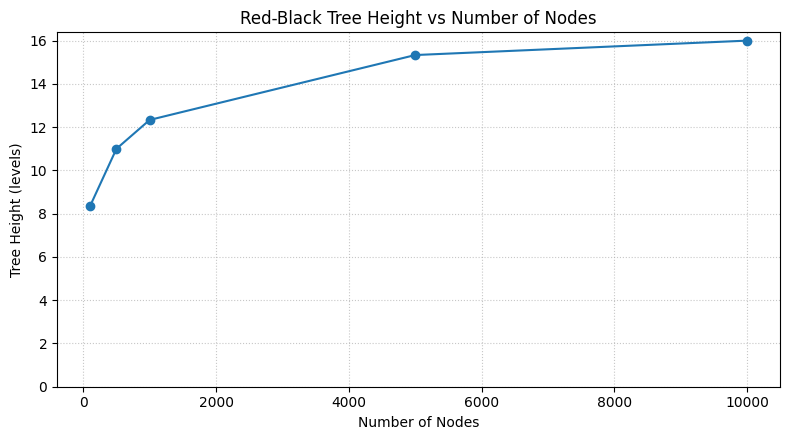

In [17]:
plot_metric(task6_df, "Height", "Tree Height (levels)",
            "Red-Black Tree Height vs Number of Nodes", "q6_height.png")

## Iterations (Insertion) v/s Node Count

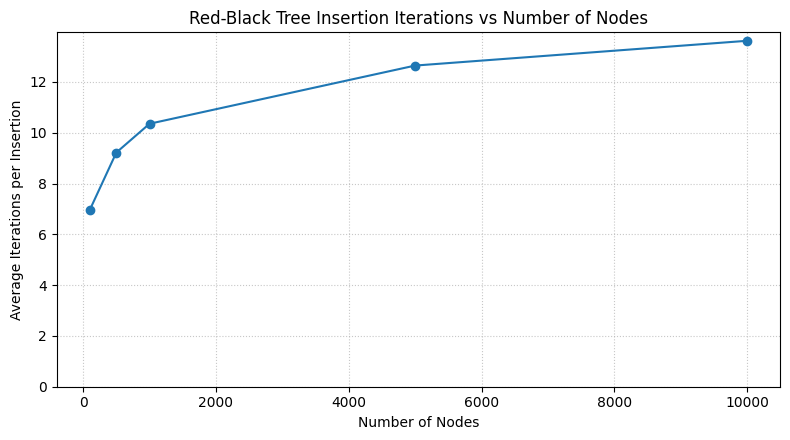

In [18]:
plot_metric(task6_df, "Average Insertion Iterations", "Average Iterations per Insertion",
            "Red-Black Tree Insertion Iterations vs Number of Nodes", "q6_insertion.png")

## Iterations (Deletion) v/s Node Count

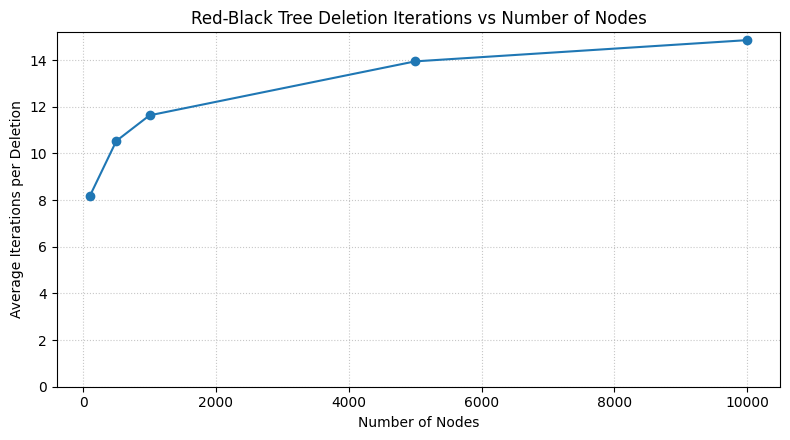

In [19]:
plot_metric(task6_df, "Average Deletion Iterations", "Average Iterations per Deletion",
            "Red-Black Tree Deletion Iterations vs Number of Nodes", "q6_deletion.png")

## Iterations (Search) v/s Node Count

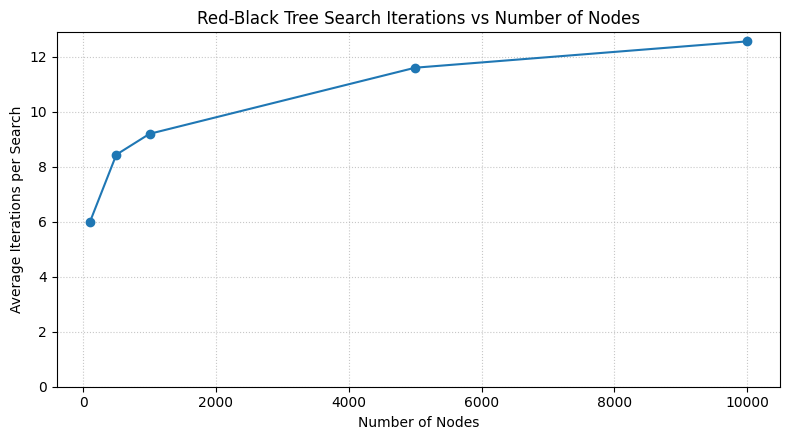

In [20]:
plot_metric(task6_df, "Average Search Iterations", "Average Iterations per Search",
            "Red-Black Tree Search Iterations vs Number of Nodes", "q6_search.png")

# Q7

Implement an ordinary Binary Search Tree (BST) and experimentally compare its search time and height with the Red-Black Tree.

The BST is implemented above; both trees are built from the same random windows of `input0.txt`.

In [21]:
task7_df = run_experiment(trees=[BST_TREE, RB_TREE], orders=["Random"])
(task7_df.pivot(index="Nodes", columns="Tree", values=["Height", "Average Search Iterations"])
         .swaplevel(axis=1).sort_index(axis=1))

Tree                        BST                       Red-Black Tree  \
      Average Search Iterations     Height Average Search Iterations   
Nodes                                                                  
100                    7.716667  13.333333                  5.960000   
500                   10.076667  18.333333                  8.300000   
1000                  11.883333  20.666667                  9.353333   
5000                  14.810000  27.666667                 11.443333   
10000                 16.333333  30.666667                 12.770000   

Tree              
          Height  
Nodes             
100     8.000000  
500    11.000000  
1000   12.333333  
5000   15.000000  
10000  16.333333

## Height Comparison

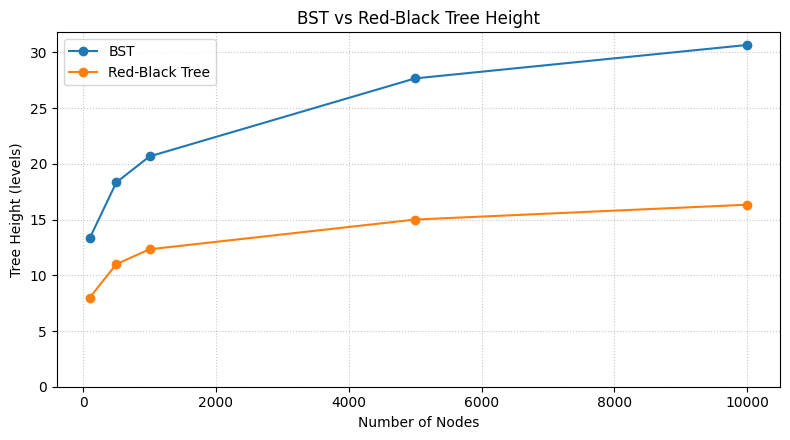

In [22]:
plot_metric(task7_df, "Height", "Tree Height (levels)",
            "BST vs Red-Black Tree Height", "q7_height.png")

## Search Comparison

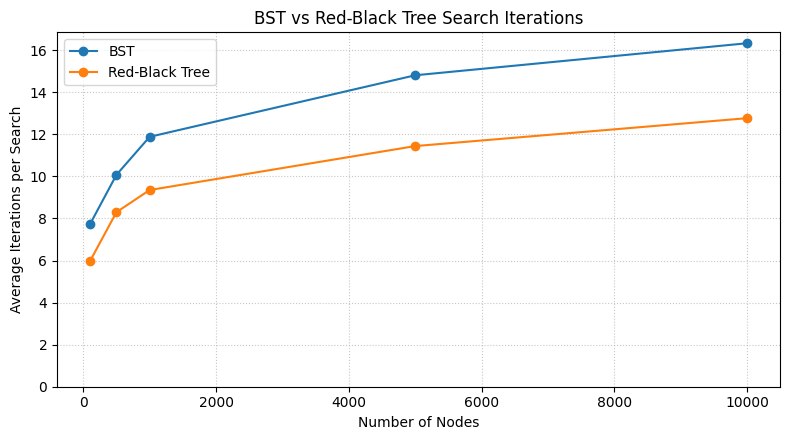

In [23]:
plot_metric(task7_df, "Average Search Iterations", "Average Iterations per Search",
            "BST vs Red-Black Tree Search Iterations", "q7_search.png")

# Q8

Experiment using random, sorted, and reverse-sorted input data and provide a brief analysis of the results.

For each size, the same distinct keys are tested in all three input orders. Insertion work is collected while building each tree, successful searches are measured before deletion, and `min(100, n // 10)` keys are then deleted. Each panel has its own y-scale, so the very different magnitudes of the BST (degenerate input) and the Red-Black Tree are visible in the axis ranges.

In [24]:
task8_df = run_experiment(trees=[BST_TREE, RB_TREE], orders=["Random", "Sorted", "Reverse Sorted"])
task8_df

,Nodes,Input Order,Tree,Height,Average Insertion Iterations,Average Deletion Iterations,Average Search Iterations
0,100,Random,BST,13.333333,6.266667,8.900000,7.266667
1,100,Random,Red-Black Tree,8.000000,6.910000,7.900000,5.946667
2,100,Sorted,BST,100.000000,49.500000,40.666667,50.500000
3,100,Sorted,Red-Black Tree,11.000000,10.740000,10.100000,6.200000
4,100,Reverse Sorted,BST,100.000000,49.500000,57.833333,50.500000
5,100,Reverse Sorted,Red-Black Tree,11.000000,10.740000,10.700000,6.200000
6,500,Random,BST,18.000000,8.969333,11.553333,9.673333
7,500,Random,Red-Black Tree,11.000000,9.168000,10.413333,8.193333
8,500,Sorted,BST,500.000000,249.500000,245.673333,258.750000
9,500,Sorted,Red-Black Tree,15.000000,15.414000,12.606667,8.690000


## Height Comparison

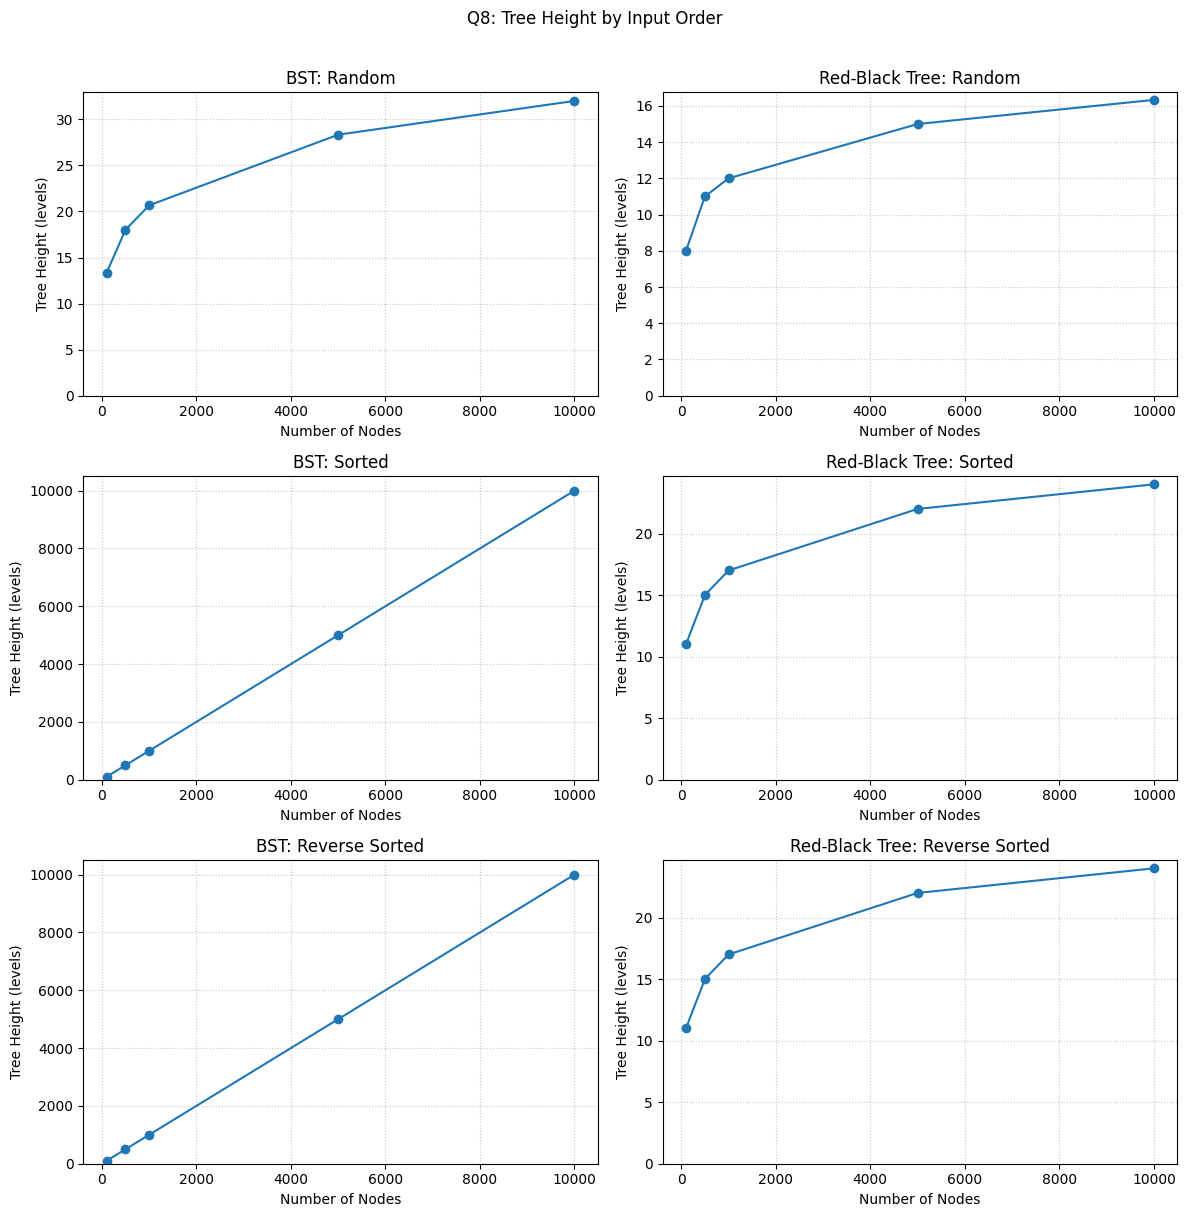

In [25]:
plot_metric_by_order(task8_df, "Height", "Tree Height (levels)",
                     "Q8: Tree Height by Input Order", "q8_height.png")

## Insertion Comparison

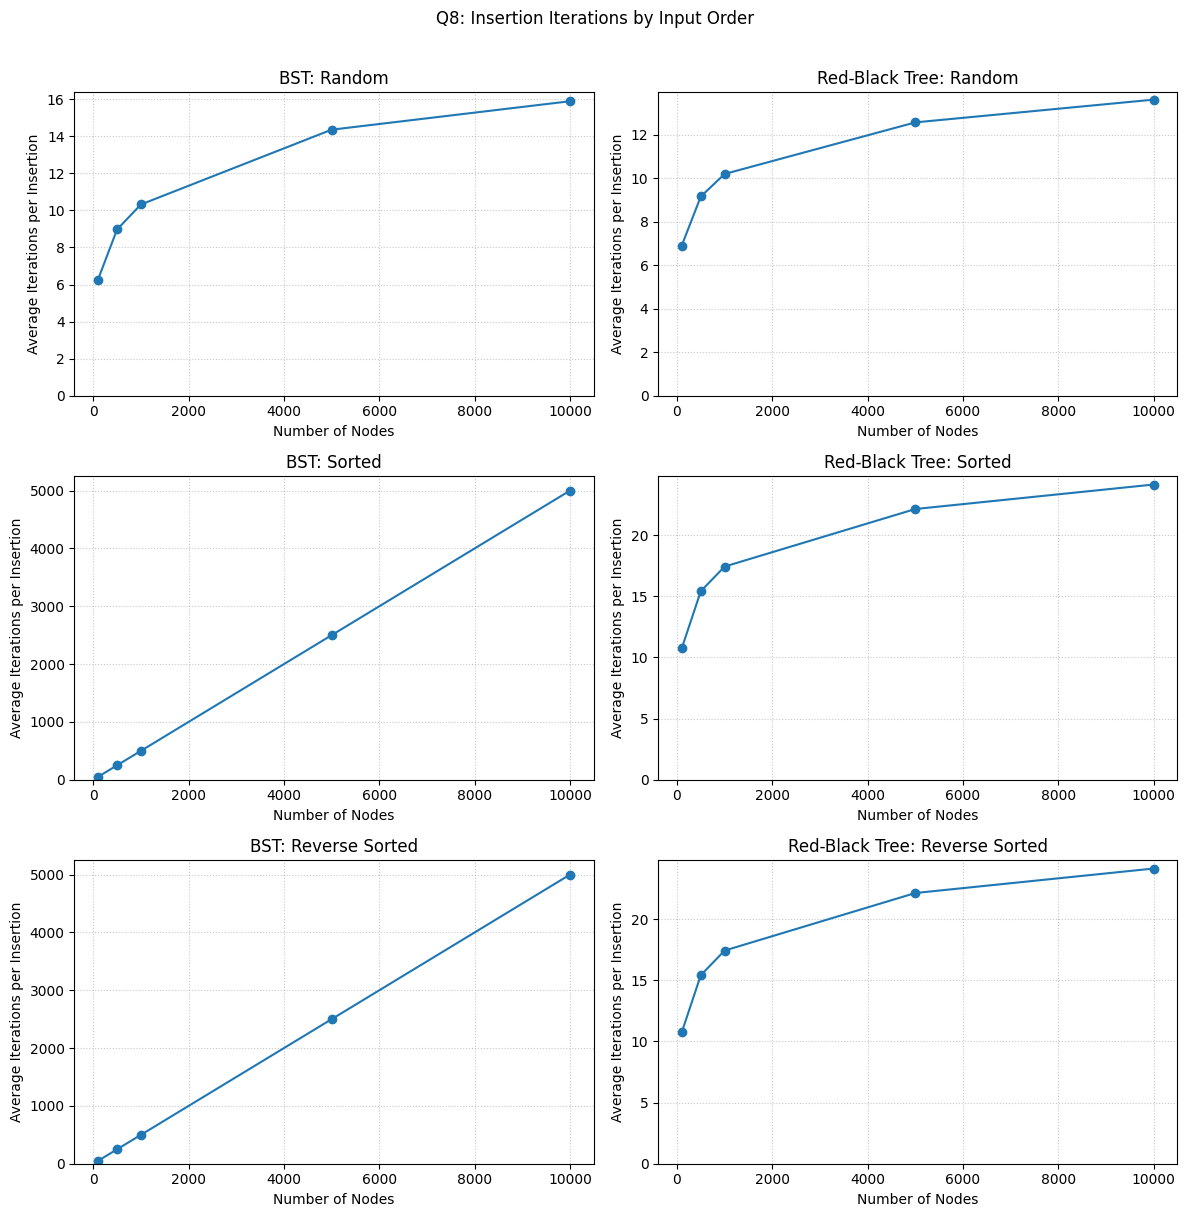

In [26]:
plot_metric_by_order(task8_df, "Average Insertion Iterations", "Average Iterations per Insertion",
                     "Q8: Insertion Iterations by Input Order", "q8_insertion.png")

## Deletion Comparison

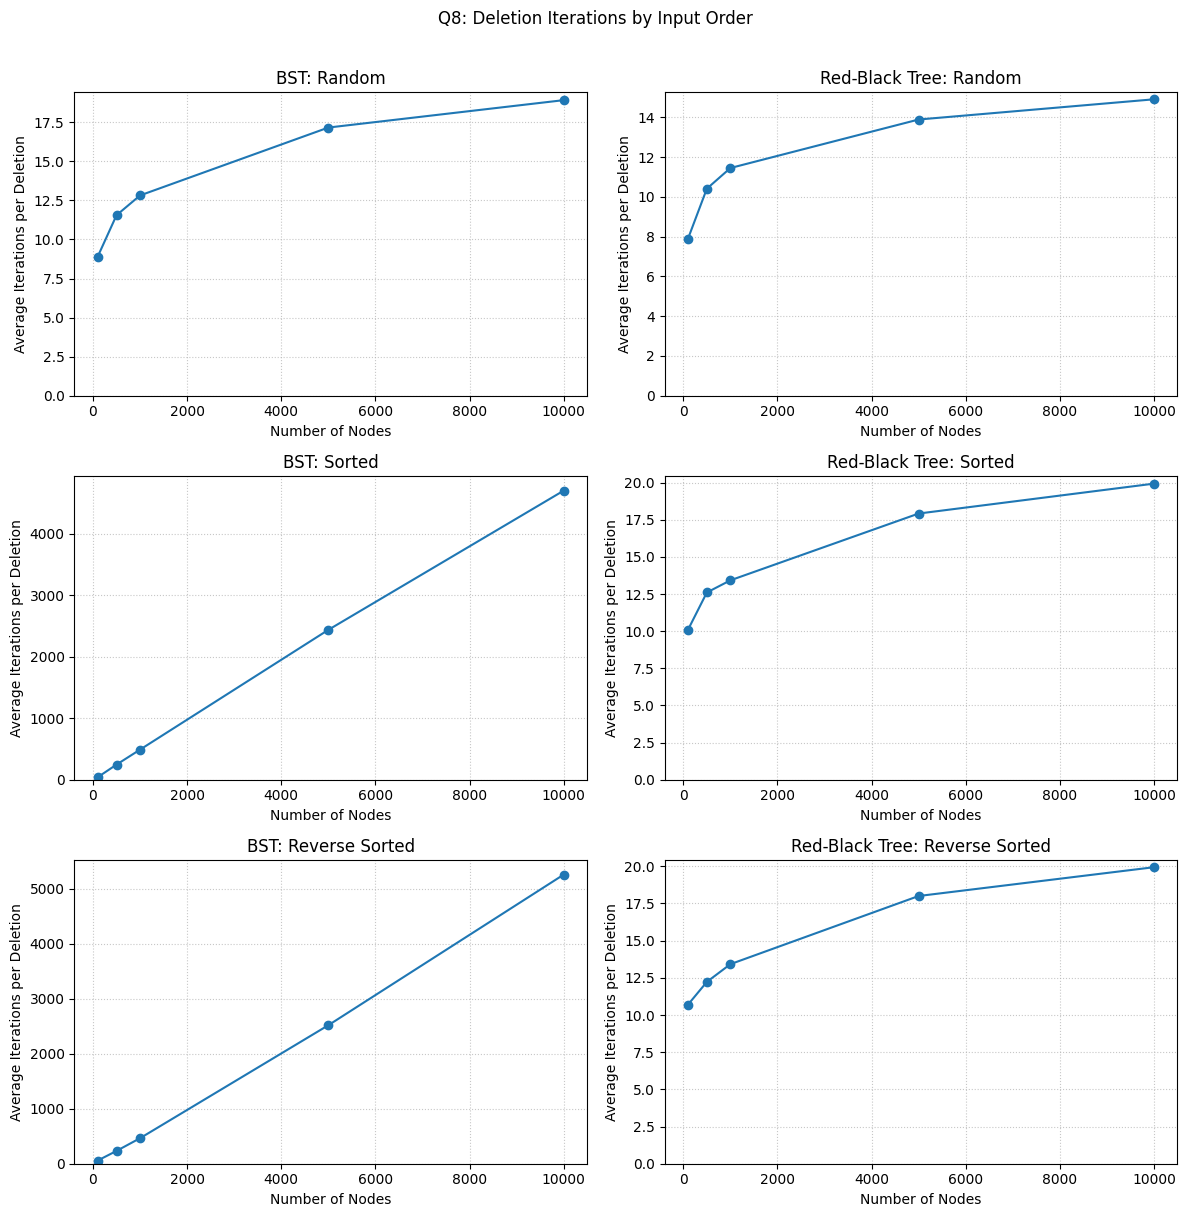

In [27]:
plot_metric_by_order(task8_df, "Average Deletion Iterations", "Average Iterations per Deletion",
                     "Q8: Deletion Iterations by Input Order", "q8_deletion.png")

## Search Comparison

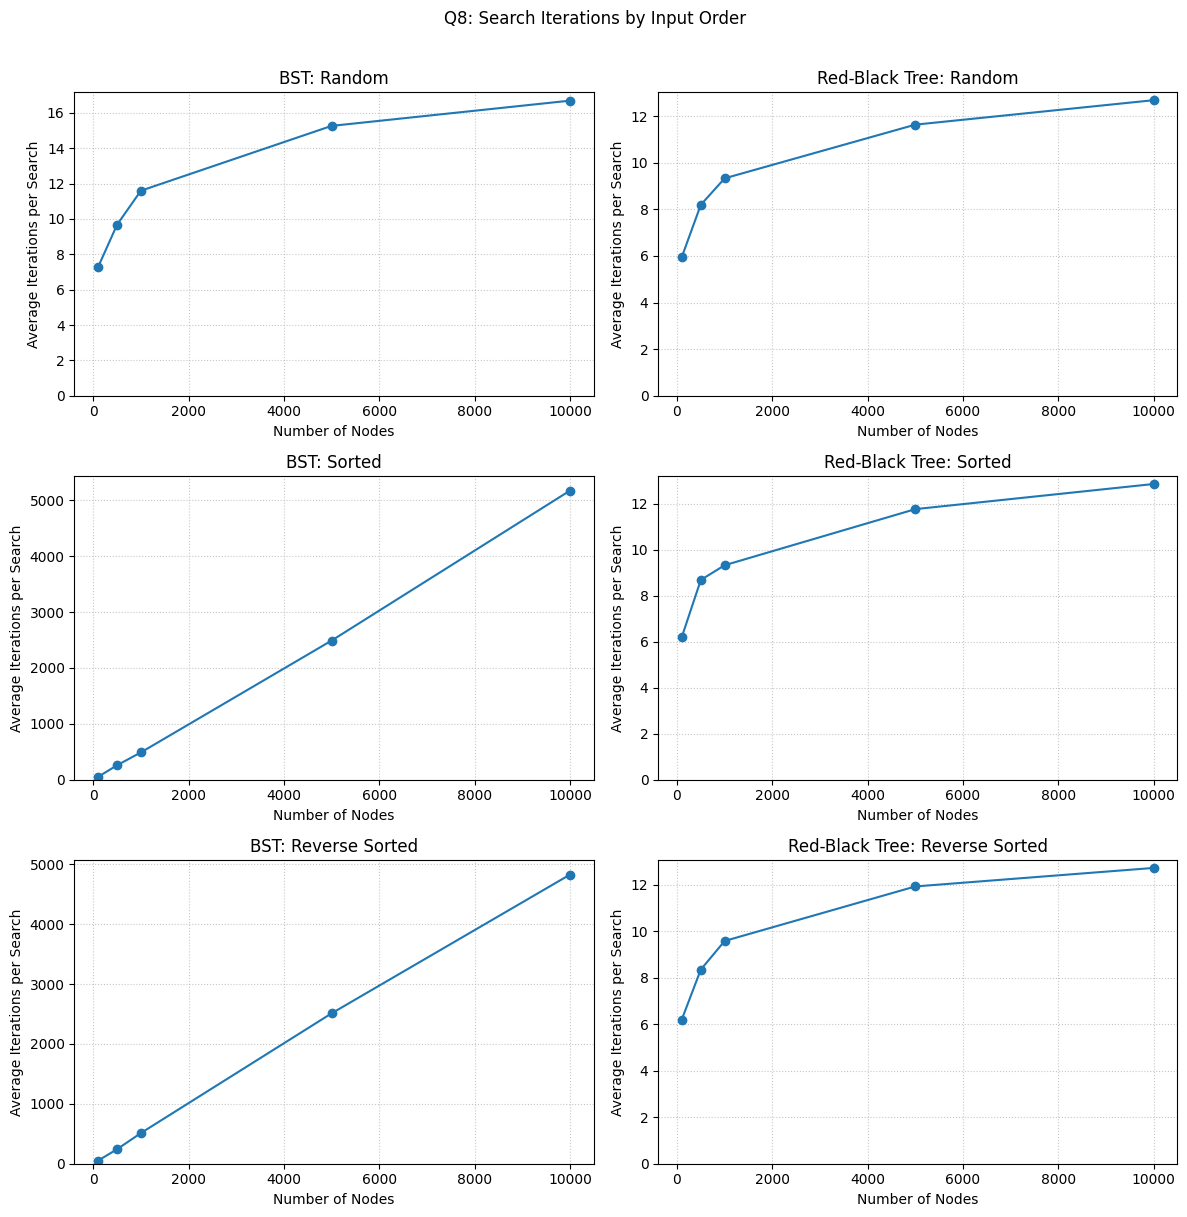

In [28]:
plot_metric_by_order(task8_df, "Average Search Iterations", "Average Iterations per Search",
                     "Q8: Search Iterations by Input Order", "q8_search.png")

## Analysis (Q8)

Numbers below are read from the Q8 table above (n = 10000, mean of `TRIALS` windows). They vary slightly with the seed, but the pattern is structural.

| Input order | Tree | Height | Avg. insertion | Avg. search | Avg. deletion |
|:--|:--|--:|--:|--:|--:|
| Random | BST | 32 | 15.9 | 16.7 | 18.9 |
| Random | Red-Black | 16.3 | 13.6 | 12.7 | 14.9 |
| Sorted | BST | 10000 | 4999.5 | 5174 | 4697 |
| Sorted | Red-Black | 24 | 24.1 | 12.9 | 19.9 |
| Reverse sorted | BST | 10000 | 4999.5 | 4827 | 5257 |
| Reverse sorted | Red-Black | 24 | 24.1 | 12.7 | 19.9 |

* **The BST depends entirely on the input order.** For random input it stays reasonably shallow (height about twice that of the Red-Black Tree). For sorted or reverse-sorted input it degenerates into a linked list: the height is exactly *n*, an insertion costs (*n* - 1)/2 iterations on average, and search and deletion cost about *n*/2. All three grow linearly, i.e. O(*n*) per operation, which is the straight line visible in the sorted BST panels of the plots.
* **The Red-Black Tree is insensitive to the input order.** Its height stays logarithmic in every case (16 levels for random and 24 for sorted input at *n* = 10000), and insertion, search and deletion cost roughly 13 to 24 iterations, growing only slowly with *n* (O(log *n*)). At *n* = 10000 sorted input is therefore about 200 times cheaper to insert into, and about 400 times cheaper to search, than in the BST.
* **Sorted input is the Red-Black Tree's most expensive case, but only mildly.** Ascending (or descending) keys always extend the same side of the tree, so the tree ends up about 50 % taller than for random keys (24 vs. 16.3 levels) and insertion costs more (24.1 vs. 13.6), because the descent is longer and re-balancing (re-colouring and rotations) is triggered often. The cost stays logarithmic. Sorted and reverse-sorted input give identical Red-Black insertion costs and heights, since the two trees are mirror images of each other.
* **For random input the two trees are close.** The Red-Black Tree is still slightly cheaper (e.g. search 12.7 vs. 16.7 iterations), and its insertion is even cheaper than the BST's, because the shorter tree outweighs the re-balancing work.
* **Caveats.** Costs are iteration counts rather than wall-clock times. The deletion averages are taken over only `min(100, n // 10)` randomly chosen keys per window, so the BST deletion values for sorted and reverse-sorted input differ somewhat from each other (4697 vs. 5257 at *n* = 10000, i.e. about +/-6 % around *n*/2).